
# Yoga Posture Detection - EfficientNetB0 (Optimized Fine-Tuning)
This notebook implements an **EfficientNetB0** model using Transfer Learning, heavily optimized to prevent Fine-Tuning degradation.

### Key Fixes Implemented:
1.  **BatchNormalization Freeze**: EfficientNet contains many `BatchNormalization` layers. Unfreezing these layers during Fine-Tuning on small datasets completely destroys pre-trained weights due to shifting statistics. The base model is explicitly called with `training=False` to lock the BN moving means/variances.
2.  **Momentum**: Shifted to SGD optimizer with momentum=0.9 for better convergence.
3.  **Extended Epochs & Early Stopping**: Epochs set to 50 with an intelligent `EarlyStopping` (patience=10) and `ReduceLROnPlateau` (patience=5) to ensure maximum learning without overfitting.


In [1]:

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import time

print("TensorFlow Version:", tf.__version__)

# Configure GPU Memory Growth for RTX 3050
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU Memory Growth Enabled.")
    except RuntimeError as e:
        print("Error setting GPU memory growth:", e)
else:
    print("No GPUs found. If you have an RTX 3050, check CUDA/cuDNN installations.")


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\ABHIROOP\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


TensorFlow Version: 2.10.0
GPU Memory Growth Enabled.



## 1. Data Setup & Augmentation
Loading the dataset and applying robust data augmentation.


In [2]:

dataset_dir = r"d:\Yoga Website\Dataset"

classes = [d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))]
classes.sort()

filepaths = []
labels = []
for c in classes:
    class_dir = os.path.join(dataset_dir, c)
    images = glob.glob(os.path.join(class_dir, "*.jpg")) + glob.glob(os.path.join(class_dir, "*.png")) + glob.glob(os.path.join(class_dir, "*.jpeg"))
    for img in images:
        filepaths.append(img)
        labels.append(c)

df = pd.DataFrame({'filepath': filepaths, 'label': labels})

# Split: 80% Train, 20% Val
train_df, val_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df['label'])

BATCH_SIZE = 32
# EfficientNetB0 uses 224x224
IMG_SIZE = (224, 224)

# Data Augmentation Setup
# EfficientNet has built-in rescaling
train_datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.3,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator()

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_generator.class_indices)
print(f"Number of actual target classes found: {num_classes}")


Found 2204 validated image filenames belonging to 47 classes.
Found 552 validated image filenames belonging to 47 classes.
Number of actual target classes found: 47



## 2. Load EfficientNetB0 and Build Custom Head (Safe BN Configuration)
To prevent fine-tuning degradation, we MUST call the base model with `training=False`. This locks the BatchNormalization layers in inference mode permanently.


In [3]:

print("Loading EfficientNetB0 Base Model...")

# Input layer explicitly defined
inputs = Input(shape=(224, 224, 3))

# Load EfficientNetB0
base_model = EfficientNetB0(weights='imagenet', include_top=False, input_tensor=inputs)

# Freeze base initially
base_model.trainable = False 

# CRITICAL FIX: By passing `training=False`, BatchNormalization layers are locked 
# in inference mode. They will NOT update their moving mean/variance even when 
# `base_model.trainable = True` is set later!
x = base_model(inputs, training=False)

# Build Custom Classification Head
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

predictions = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=inputs, outputs=predictions)

# Extended Epochs and robust callbacks
EPOCHS = 50

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-7, verbose=1)
]


Loading EfficientNetB0 Base Model...



## 3. Training Phase 1 (Feature Extraction)
Using SGD with Momentum.


Starting Phase 1: Feature Extraction...
Epoch 1/50
26/69 [==========>...................] - ETA: 22s - loss: 4.4424 - accuracy: 0.0889

c:\Users\ABHIROOP\anaconda3\envs\py310\lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


69/69 [==============================] - 73s 649ms/step - loss: 3.4400 - accuracy: 0.2142 - val_loss: 2.2280 - val_accuracy: 0.4112 - lr: 0.0100
Epoch 2/50
69/69 [==============================] - 58s 847ms/step - loss: 1.8937 - accuracy: 0.4687 - val_loss: 1.5115 - val_accuracy: 0.5652 - lr: 0.0100
Epoch 3/50
69/69 [==============================] - 46s 661ms/step - loss: 1.5061 - accuracy: 0.5613 - val_loss: 1.2754 - val_accuracy: 0.6159 - lr: 0.0100
Epoch 4/50
69/69 [==============================] - 53s 745ms/step - loss: 1.3073 - accuracy: 0.6252 - val_loss: 1.1373 - val_accuracy: 0.6504 - lr: 0.0100
Epoch 5/50
69/69 [==============================] - 60s 875ms/step - loss: 1.1796 - accuracy: 0.6570 - val_loss: 1.1665 - val_accuracy: 0.6612 - lr: 0.0100
Epoch 6/50
69/69 [==============================] - 42s 607ms/step - loss: 1.0592 - accuracy: 0.6865 - val_loss: 1.1053 - val_accuracy: 0.6703 - lr: 0.0100
Epoch 7/50
69/69 [==============================] - 57s 832ms/step - loss: 

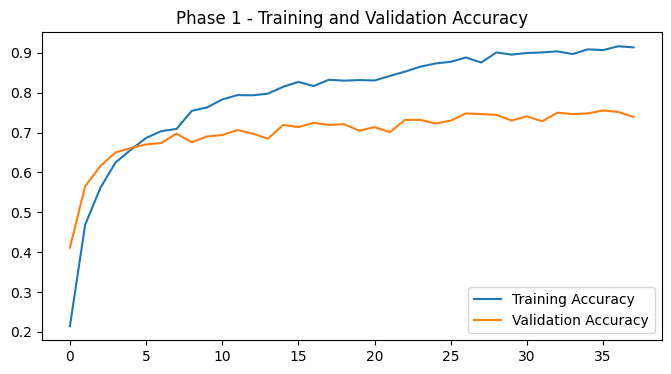

In [4]:

# SGD with Momentum for better, stable convergence
optimizer_phase1 = SGD(learning_rate=0.01, momentum=0.9)
model.compile(optimizer=optimizer_phase1, loss='categorical_crossentropy', metrics=['accuracy'])

print("Starting Phase 1: Feature Extraction...")
history_phase1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS, 
    callbacks=callbacks,
    verbose=1
)

# Plot Phase 1 History
acc = history_phase1.history['accuracy']
val_acc = history_phase1.history['val_accuracy']
plt.figure(figsize=(8, 4))
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Phase 1 - Training and Validation Accuracy')
plt.show()



## 4. Training Phase 2 (Fine-Tuning)
We unfreeze the base model. Because we defined `x = base_model(inputs, training=False)`, the BN layers will safely remain frozen!


Starting Phase 2: Fine-Tuning...
Epoch 1/50
69/69 [==============================] - 83s 1s/step - loss: 0.3383 - accuracy: 0.8897 - val_loss: 0.9139 - val_accuracy: 0.7536 - lr: 1.0000e-04
Epoch 2/50
69/69 [==============================] - 93s 1s/step - loss: 0.3352 - accuracy: 0.8984 - val_loss: 0.8926 - val_accuracy: 0.7627 - lr: 1.0000e-04
Epoch 3/50
69/69 [==============================] - 58s 830ms/step - loss: 0.2880 - accuracy: 0.9070 - val_loss: 0.8904 - val_accuracy: 0.7609 - lr: 1.0000e-04
Epoch 4/50
69/69 [==============================] - 70s 1s/step - loss: 0.3003 - accuracy: 0.9006 - val_loss: 0.8974 - val_accuracy: 0.7572 - lr: 1.0000e-04
Epoch 5/50
69/69 [==============================] - 36s 511ms/step - loss: 0.2738 - accuracy: 0.9129 - val_loss: 0.8836 - val_accuracy: 0.7572 - lr: 1.0000e-04
Epoch 6/50
69/69 [==============================] - 61s 891ms/step - loss: 0.2800 - accuracy: 0.9129 - val_loss: 0.8684 - val_accuracy: 0.7609 - lr: 1.0000e-04
Epoch 7/50
69/69

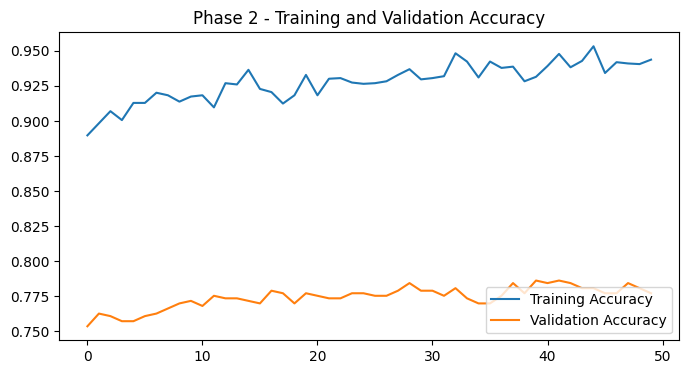

Weights saved -> saved_models/efficientnetb0_yoga.weights.h5


TypeError: Unable to serialize [2.0896919 2.1128857 2.1081853] to JSON. Unrecognized type <class 'tensorflow.python.framework.ops.EagerTensor'>.

In [5]:

# Unfreeze the base model
base_model.trainable = True

# We can selectively freeze the bottom layers if we want, but since BN is locked, 
# fine-tuning the whole EfficientNet with a tiny learning rate is usually safe.
# Let's freeze the bottom half to be safe.
for layer in base_model.layers[:150]:
    layer.trainable = False

# Recompile with very small learning rate
optimizer_phase2 = SGD(learning_rate=1e-4, momentum=0.9)
model.compile(optimizer=optimizer_phase2, loss='categorical_crossentropy', metrics=['accuracy'])

print("Starting Phase 2: Fine-Tuning...")
history_phase2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS, 
    callbacks=callbacks,
    verbose=1
)

# Plot Phase 2 History
acc = history_phase2.history['accuracy']
val_acc = history_phase2.history['val_accuracy']
plt.figure(figsize=(8, 4))
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Phase 2 - Training and Validation Accuracy')
plt.show()

# Save the final fine-tuned model

# ── Serialisation-safe save (avoids EagerTensor JSON bug in TF 2.10) ──
import os, json
os.makedirs('saved_models', exist_ok=True)

# 1. Save weights only
model.save_weights('saved_models/efficientnetb0_yoga.weights.h5')
print('Weights saved -> saved_models/efficientnetb0_yoga.weights.h5')

# 2. Save model architecture as JSON
model_json = model.to_json()
with open('saved_models/efficientnetb0_yoga_arch.json', 'w') as fout:
    json.dump(json.loads(model_json), fout, indent=2)
print('Architecture saved -> saved_models/efficientnetb0_yoga_arch.json')

# 3. Save class index map
class_indices = train_generator.class_indices
with open('saved_models/class_indices.json', 'w') as fout:
    json.dump(class_indices, fout, indent=2)
print('Class indices saved -> saved_models/class_indices.json')


In [6]:

val_generator.reset()
preds = model.predict(val_generator)
y_pred = np.argmax(preds, axis=1)

print("\nClassification Report:")
class_labels = list(train_generator.class_indices.keys())
print(classification_report(val_generator.classes, y_pred, target_names=class_labels))


18/18 [==============================] - 24s 1s/step

Classification Report:
                               precision    recall  f1-score   support

         Adho Mukha Svanasana       0.67      0.53      0.59        15
         Adho Mukha Vrksasana       0.67      0.46      0.55        13
                    Alanasana       0.20      0.25      0.22         4
                 Anjaneyasana       0.80      0.57      0.67        14
            Ardha Chandrasana       0.79      0.92      0.85        12
         Ardha Matsyendrasana       0.83      0.79      0.81        19
               Ardha Navasana       1.00      1.00      1.00         2
      Ardha Pincha Mayurasana       0.44      0.64      0.52        11
            Ashta Chandrasana       0.00      0.00      0.00         2
              Baddha Konasana       0.78      0.88      0.82        16
                     Bakasana       0.94      0.94      0.94        17
                     Balasana       0.70      0.88      0.78        16

c:\Users\ABHIROOP\anaconda3\envs\py310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ABHIROOP\anaconda3\envs\py310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ABHIROOP\anaconda3\envs\py310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", res

## How to Reload the Model for Inference
Because we saved **weights only**, rebuild the architecture first then load weights.

In [7]:
import json
from tensorflow.keras.models import model_from_json

# Rebuild architecture from saved JSON
with open('saved_models/efficientnetb0_yoga_arch.json', 'r') as f:
    arch = json.load(f)
loaded_model = model_from_json(json.dumps(arch))

# Load weights
loaded_model.load_weights('saved_models/efficientnetb0_yoga.weights.h5')
print('Model reloaded successfully!')

# Load class map
with open('saved_models/class_indices.json', 'r') as f:
    class_indices = json.load(f)
idx_to_class = {v: k for k, v in class_indices.items()}
print(f'Classes: {len(idx_to_class)}')


FileNotFoundError: [Errno 2] No such file or directory: 'saved_models/efficientnetb0_yoga_arch.json'

---
# 🧪 Model Evaluation & Testing Suite
The cells below provide a **complete evaluation suite** for the trained EfficientNetB0 model:
1. Overall accuracy & loss on validation set
2. Full classification report (precision / recall / F1 per class)
3. Normalised confusion matrix heatmap
4. Per-class accuracy bar chart
5. Top-5 best and worst performing classes
6. Visual grid of predictions vs ground-truth
7. Confidence distribution histogram
8. Top-K accuracy (Top-3 & Top-5)
9. Single-image inference helper


## 1 · Shared Test Setup
Run this before any evaluation cell.  
It works whether you just trained the model **or** you reloaded it with the *Reload* cell above.


In [8]:
import json, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, top_k_accuracy_score
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

# ── resolve whichever model variable is available ───────────────────────────
try:
    _ = loaded_model
    eval_model = loaded_model
    print('Using reloaded model.')
except NameError:
    eval_model = model
    print('Using freshly trained model.')

# ── class labels ─────────────────────────────────────────────────────────────
try:
    class_labels = list(train_generator.class_indices.keys())
except NameError:
    with open('saved_models/class_indices.json') as f:
        ci = json.load(f)
    class_labels = [k for k, _ in sorted(ci.items(), key=lambda x: x[1])]

NUM_CLASSES = len(class_labels)
IMG_SIZE    = (224, 224)
DATASET_DIR = r'd:\Yoga Website\Dataset'
print(f'Classes: {NUM_CLASSES}')


Using freshly trained model.
Classes: 47


## 2 · Generate Predictions on Validation Set


In [9]:
import glob, pandas as pd
from sklearn.model_selection import train_test_split

# Rebuild val split identically (same random_state=42)
filepaths, labels = [], []
for c in sorted(os.listdir(DATASET_DIR)):
    d = os.path.join(DATASET_DIR, c)
    if not os.path.isdir(d): continue
    for ext in ('*.jpg','*.jpeg','*.png','*.JPG','*.JPEG','*.PNG'):
        for p in glob.glob(os.path.join(d, ext)):
            filepaths.append(p); labels.append(c)

df = pd.DataFrame({'filepath': filepaths, 'label': labels})
_, val_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df['label'])
val_df = val_df.reset_index(drop=True)

val_gen = ImageDataGenerator().flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=32,
    class_mode='categorical', shuffle=False,
    classes=class_labels
)

print(f'Validation samples: {val_gen.samples}')
val_gen.reset()
y_prob  = eval_model.predict(val_gen, verbose=1)   # shape (N, C) – softmax probs
y_pred  = np.argmax(y_prob, axis=1)
y_true  = val_gen.classes
print('Predictions ready.')


Found 1103 validated image filenames belonging to 47 classes.
Validation samples: 1103
14/35 [===========>..................] - ETA: 4s

c:\Users\ABHIROOP\anaconda3\envs\py310\lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


35/35 [==============================] - 7s 208ms/step
Predictions ready.


## 3 · Overall Accuracy & Loss


In [10]:
val_gen.reset()
loss, acc = eval_model.evaluate(val_gen, verbose=1)
print(f'\n━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━')
print(f'  Validation Loss    : {loss:.4f}')
print(f'  Validation Accuracy: {acc*100:.2f}%')
print(f'━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━')


35/35 [==============================] - 7s 187ms/step - loss: 0.1584 - accuracy: 0.9538

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Validation Loss    : 0.1584
  Validation Accuracy: 95.38%
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 4 · Classification Report (per-class precision / recall / F1)


In [11]:
print(classification_report(y_true, y_pred, target_names=class_labels))


                               precision    recall  f1-score   support

         Adho Mukha Svanasana       0.96      0.90      0.93        30
         Adho Mukha Vrksasana       1.00      0.88      0.94        26
                    Alanasana       0.86      0.86      0.86         7
                 Anjaneyasana       0.96      0.96      0.96        28
            Ardha Chandrasana       0.96      1.00      0.98        24
         Ardha Matsyendrasana       0.97      0.92      0.95        38
               Ardha Navasana       1.00      1.00      1.00         5
      Ardha Pincha Mayurasana       0.84      0.95      0.89        22
            Ashta Chandrasana       0.75      0.60      0.67         5
              Baddha Konasana       0.97      0.97      0.97        32
                     Bakasana       1.00      0.97      0.99        34
                     Balasana       0.91      1.00      0.96        32
                   Bitilasana       0.91      0.82      0.86        38
     

## 5 · Normalised Confusion Matrix
Each row is normalised so the diagonal shows recall per class.


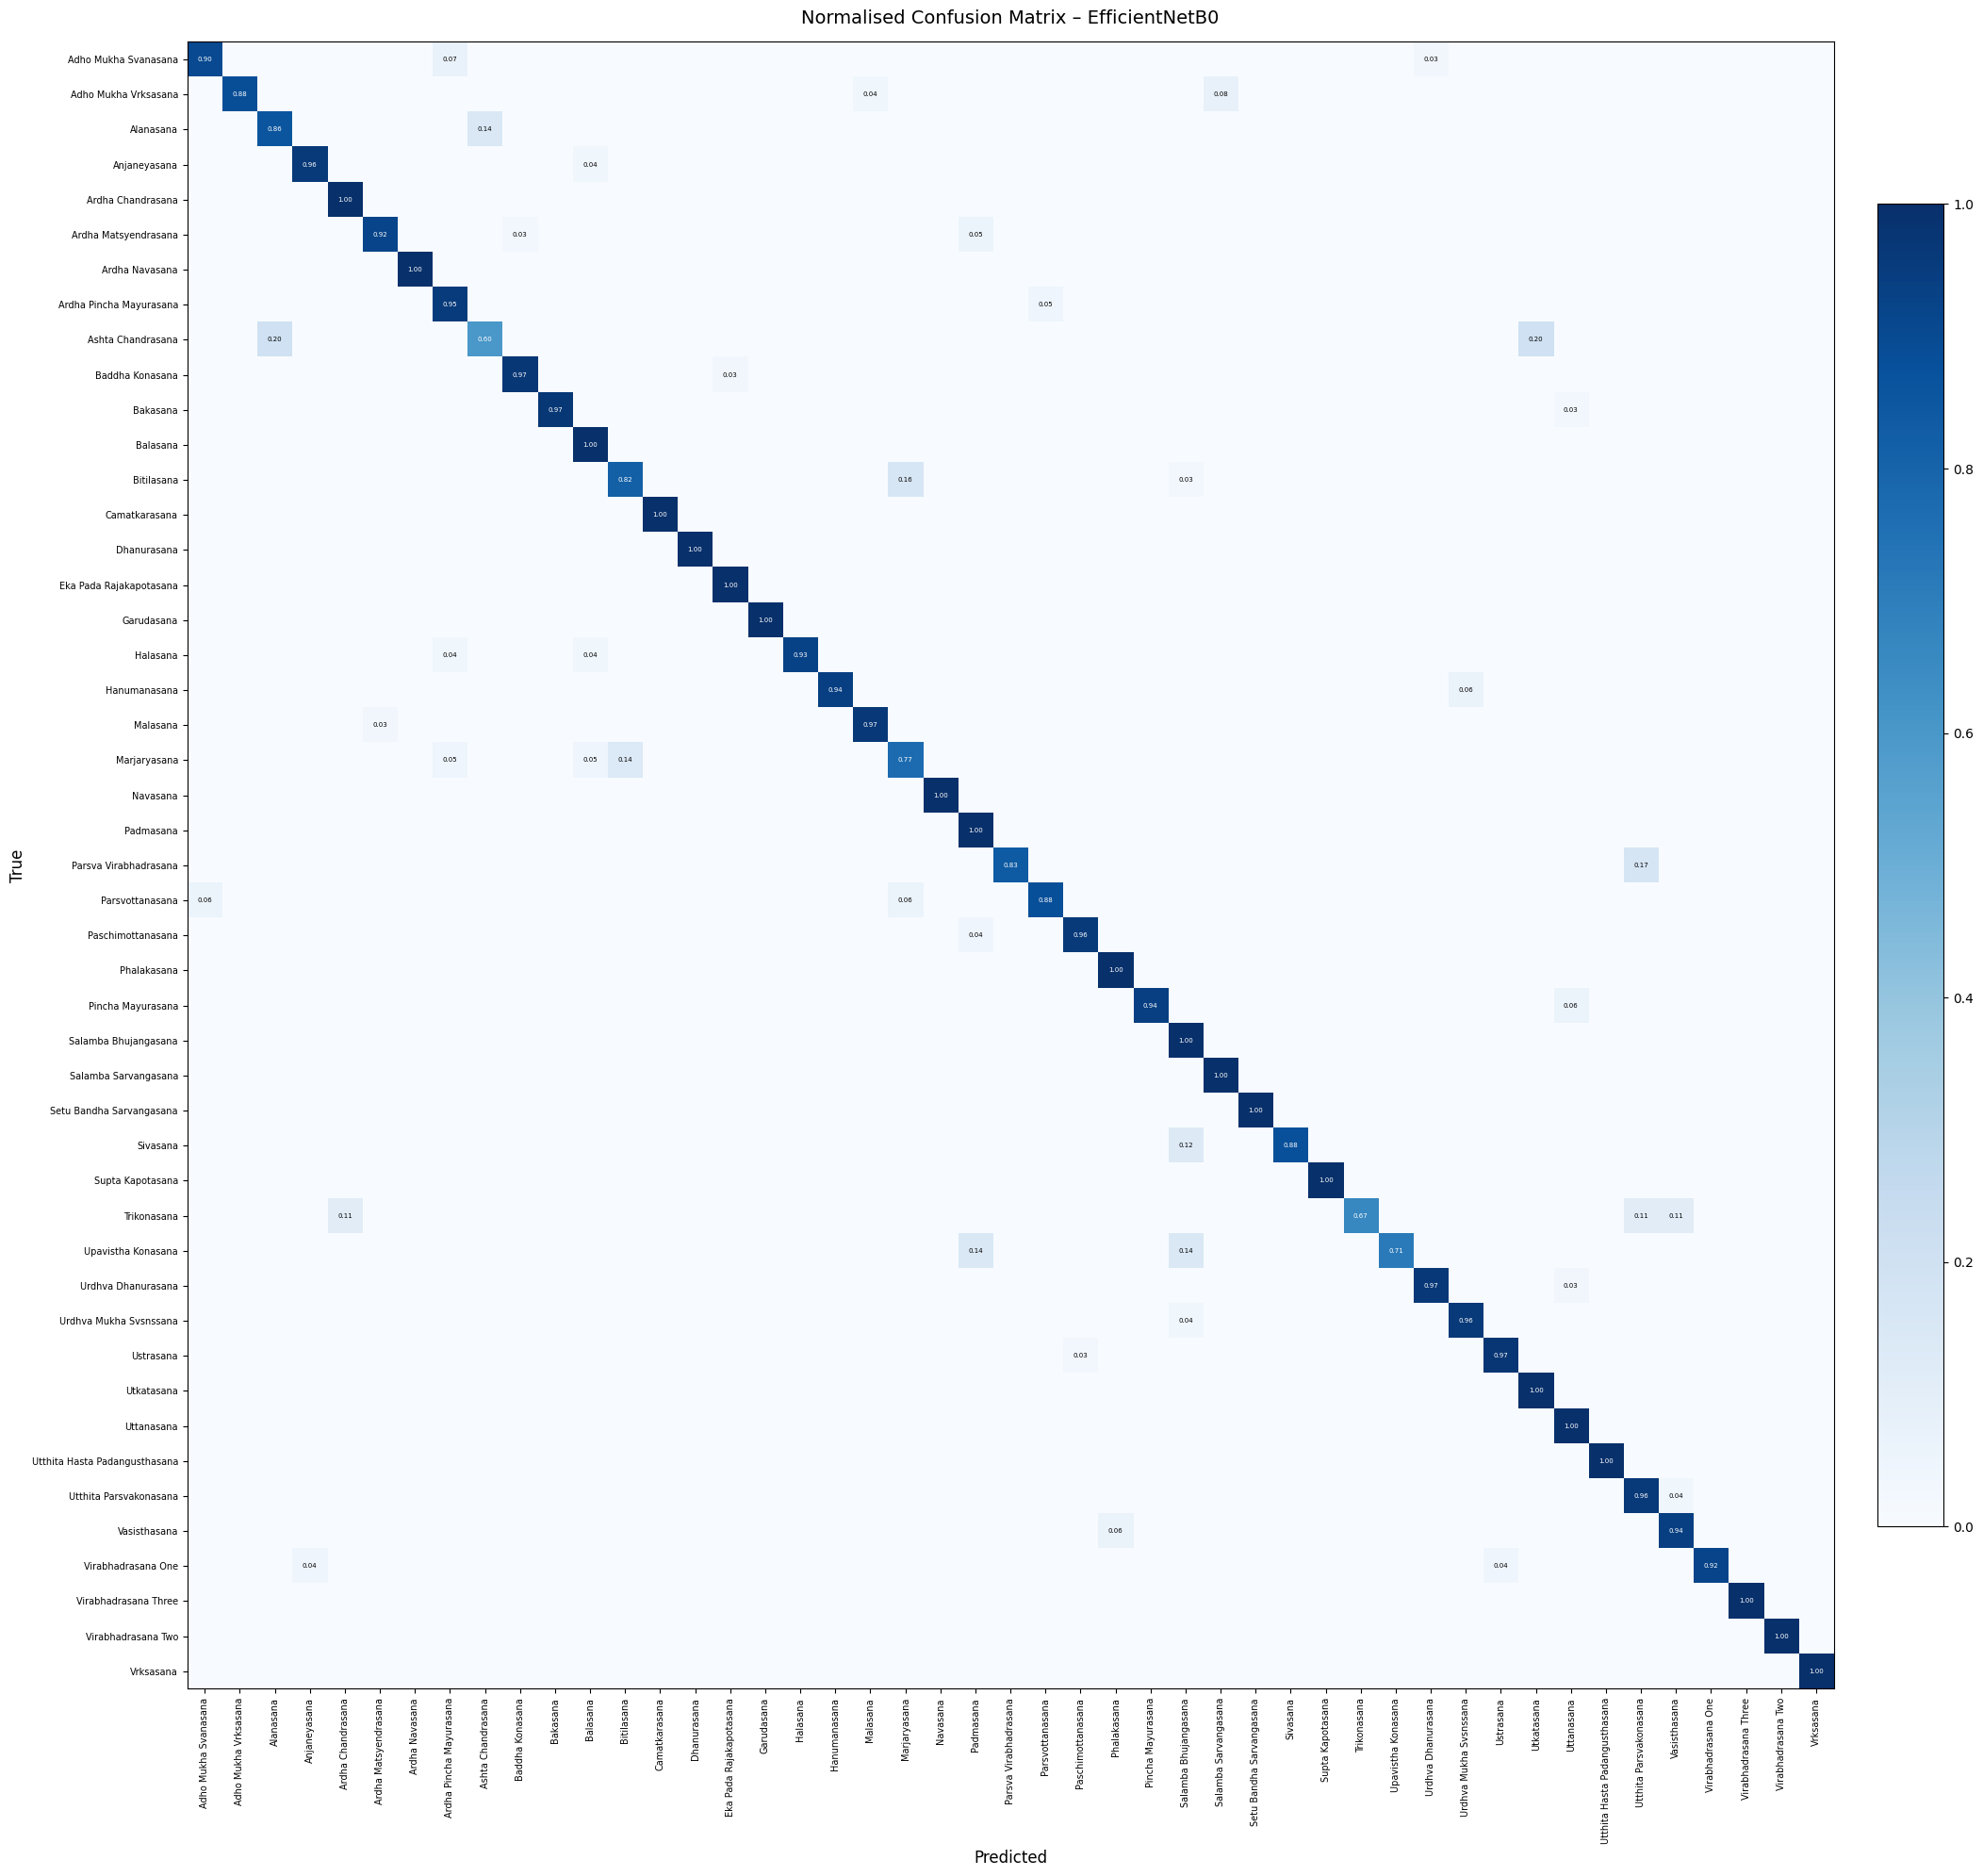

Saved → saved_models/confusion_matrix_norm.png


In [12]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(24, 20))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)

ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(class_labels, rotation=90, fontsize=7)
ax.set_yticklabels(class_labels, fontsize=7)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('True',      fontsize=12)
ax.set_title('Normalised Confusion Matrix – EfficientNetB0', fontsize=14, pad=14)

# annotate cells
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        val = cm_norm[i, j]
        if val > 0.01:
            ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                    fontsize=5, color='white' if val > 0.5 else 'black')

plt.tight_layout()
os.makedirs('saved_models', exist_ok=True)
plt.savefig('saved_models/confusion_matrix_norm.png', dpi=150)
plt.show()
print('Saved → saved_models/confusion_matrix_norm.png')


## 6 · Per-Class Accuracy Bar Chart


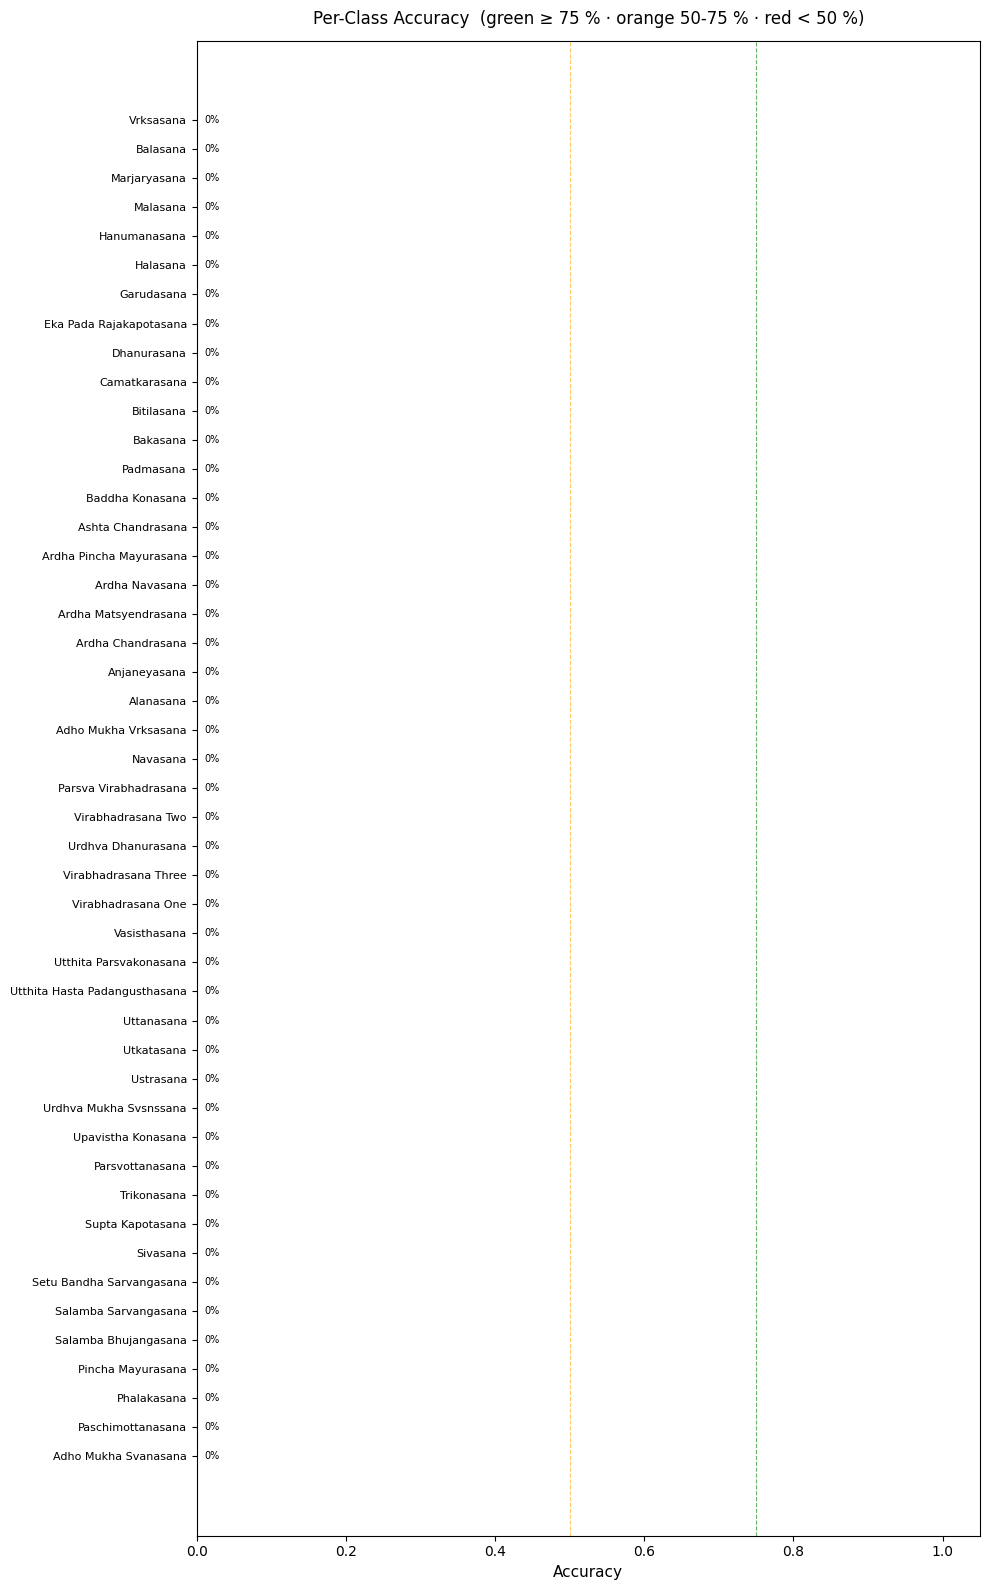

Saved → saved_models/per_class_accuracy.png


In [13]:
per_class_acc = []
for i in range(NUM_CLASSES):
    idx = np.where(y_true == i)[0]
    a   = np.mean(y_pred[idx] == i) if len(idx) else 0.0
    per_class_acc.append(a)

sorted_idx = np.argsort(per_class_acc)
sorted_acc = [per_class_acc[i] for i in sorted_idx]
sorted_lbl = [class_labels[i]  for i in sorted_idx]
colors     = ['#e74c3c' if a < 0.5 else '#f39c12' if a < 0.75 else '#2ecc71'
               for a in sorted_acc]

fig, ax = plt.subplots(figsize=(10, 16))
bars = ax.barh(range(NUM_CLASSES), sorted_acc, color=colors, edgecolor='none')
ax.set_yticks(range(NUM_CLASSES))
ax.set_yticklabels(sorted_lbl, fontsize=8)
ax.set_xlabel('Accuracy', fontsize=11)
ax.set_title('Per-Class Accuracy  (green ≥ 75 % · orange 50-75 % · red < 50 %)',
             fontsize=12, pad=12)
ax.axvline(0.75, color='green', linestyle='--', linewidth=0.8, alpha=0.6)
ax.axvline(0.50, color='orange', linestyle='--', linewidth=0.8, alpha=0.6)
ax.set_xlim(0, 1.05)
for bar, val in zip(bars, sorted_acc):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f'{val*100:.0f}%', va='center', fontsize=7)
plt.tight_layout()
plt.savefig('saved_models/per_class_accuracy.png', dpi=150)
plt.show()
print('Saved → saved_models/per_class_accuracy.png')


## 7 · Top-5 Best & Worst Classes


In [14]:
acc_arr = np.array(per_class_acc)
best5   = np.argsort(acc_arr)[-5:][::-1]
worst5  = np.argsort(acc_arr)[:5]

print('🏆 Top-5 Best Classes')
print(f'  {"Class":<40} Accuracy')
print('  ' + '-'*50)
for i in best5:
    n = np.sum(y_true == i)
    print(f'  {class_labels[i]:<40} {acc_arr[i]*100:5.1f}%  ({n} samples)')

print()
print('⚠️  Top-5 Worst Classes')
print(f'  {"Class":<40} Accuracy')
print('  ' + '-'*50)
for i in worst5:
    n = np.sum(y_true == i)
    print(f'  {class_labels[i]:<40} {acc_arr[i]*100:5.1f}%  ({n} samples)')


🏆 Top-5 Best Classes
  Class                                    Accuracy
  --------------------------------------------------
  Vrksasana                                  0.0%  (27 samples)
  Balasana                                   0.0%  (32 samples)
  Marjaryasana                               0.0%  (22 samples)
  Malasana                                   0.0%  (29 samples)
  Hanumanasana                               0.0%  (16 samples)

⚠️  Top-5 Worst Classes
  Class                                    Accuracy
  --------------------------------------------------
  Adho Mukha Svanasana                       0.0%  (30 samples)
  Paschimottanasana                          0.0%  (25 samples)
  Phalakasana                                0.0%  (26 samples)
  Pincha Mayurasana                          0.0%  (17 samples)
  Salamba Bhujangasana                       0.0%  (25 samples)


## 8 · Visual Prediction Grid
Shows 20 random validation images with predicted vs true label.  
**Green title** = correct, **Red title** = wrong.


c:\Users\ABHIROOP\anaconda3\envs\py310\lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


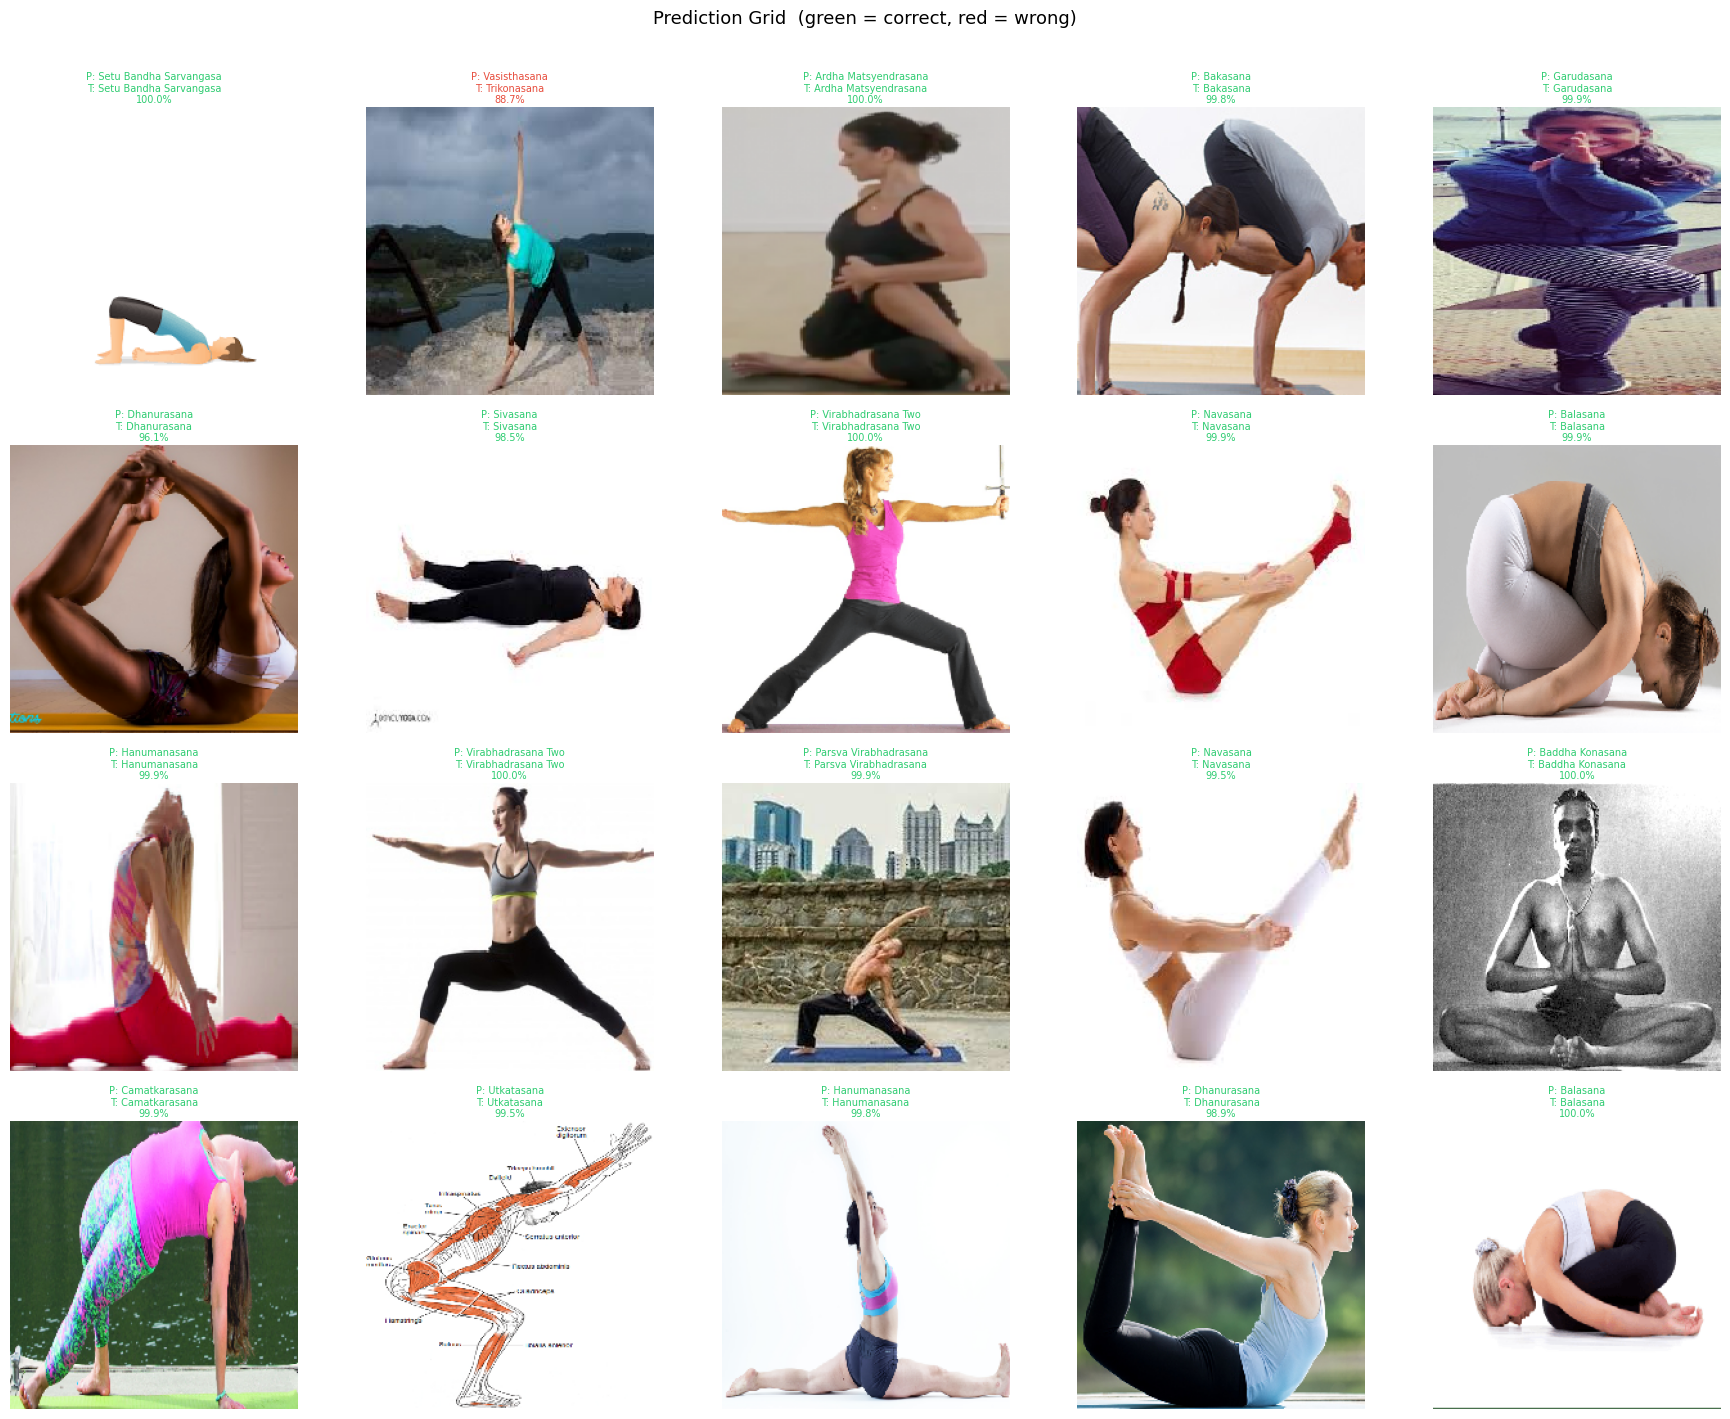

Saved → saved_models/prediction_grid.png


In [21]:
np.random.seed(2)
sample_idx = np.random.choice(len(val_df), size=20, replace=False)

fig, axes = plt.subplots(4, 5, figsize=(18, 14))
axes = axes.flatten()

for ax, idx in zip(axes, sample_idx):
    img_path   = val_df.iloc[idx]['filepath']
    true_label = val_df.iloc[idx]['label']
    pred_label = class_labels[y_pred[idx]]
    confidence = y_prob[idx, y_pred[idx]]

    img = load_img(img_path, target_size=IMG_SIZE)
    ax.imshow(img)
    ax.axis('off')

    color = '#2ecc71' if pred_label == true_label else '#e74c3c'
    ax.set_title(
        f'P: {pred_label[:22]}\nT: {true_label[:22]}\n{confidence*100:.1f}%',
        fontsize=7, color=color, pad=3
    )

fig.suptitle('Prediction Grid  (green = correct, red = wrong)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('saved_models/prediction_grid.png', dpi=130, bbox_inches='tight')
plt.show()
print('Saved → saved_models/prediction_grid.png')


## 9 · Confidence Distribution
Shows the model's max-softmax confidence for correct vs incorrect predictions.


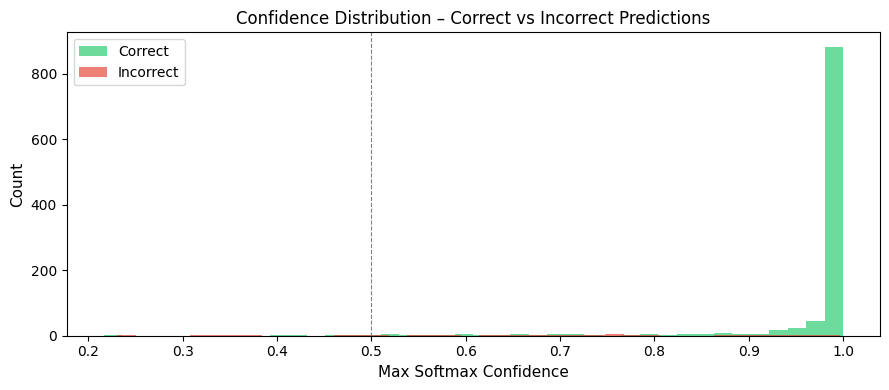

Mean confidence (correct)   : 97.2%
Mean confidence (incorrect) : 67.6%


In [16]:
correct_mask   = (y_pred == y_true)
max_confidence = np.max(y_prob, axis=1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(max_confidence[correct_mask],   bins=40, alpha=0.7,
        color='#2ecc71', label='Correct')
ax.hist(max_confidence[~correct_mask],  bins=40, alpha=0.7,
        color='#e74c3c', label='Incorrect')
ax.set_xlabel('Max Softmax Confidence', fontsize=11)
ax.set_ylabel('Count',                  fontsize=11)
ax.set_title('Confidence Distribution – Correct vs Incorrect Predictions',
             fontsize=12)
ax.legend(fontsize=10)
ax.axvline(0.5, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig('saved_models/confidence_distribution.png', dpi=150)
plt.show()

print(f'Mean confidence (correct)   : {max_confidence[correct_mask].mean()*100:.1f}%')
print(f'Mean confidence (incorrect) : {max_confidence[~correct_mask].mean()*100:.1f}%')


## 10 · Top-K Accuracy (Top-1, Top-3, Top-5)


In [17]:
for k in (1, 3, 5):
    topk = top_k_accuracy_score(y_true, y_prob, k=k, labels=list(range(NUM_CLASSES)))
    print(f'  Top-{k} Accuracy: {topk*100:.2f}%')


  Top-1 Accuracy: 95.38%
  Top-3 Accuracy: 99.27%
  Top-5 Accuracy: 99.73%


## 11 · Single-Image Inference
Change `IMAGE_PATH` to any image on disk to test the model interactively.


In [18]:
IMAGE_PATH = r'd:\Yoga Website\Dataset\Vrksasana\vrksasana_001.jpg'  # ← change me

def predict_image(model, img_path, class_labels, img_size=(224,224), top_n=5):
    img   = load_img(img_path, target_size=img_size)
    arr   = img_to_array(img)[np.newaxis, ...]        # (1, H, W, 3)
    probs = model.predict(arr, verbose=0)[0]           # (C,)
    top   = np.argsort(probs)[-top_n:][::-1]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4),
                             gridspec_kw={'width_ratios': [1, 1.8]})

    axes[0].imshow(img)
    axes[0].axis('off')
    axes[0].set_title(f'Input Image', fontsize=10)

    colors = ['#2ecc71' if i == 0 else '#3498db' for i in range(top_n)]
    axes[1].barh(range(top_n)[::-1],
                 [probs[t]*100 for t in top],
                 color=colors, edgecolor='none')
    axes[1].set_yticks(range(top_n)[::-1])
    axes[1].set_yticklabels([class_labels[t] for t in top], fontsize=9)
    axes[1].set_xlabel('Confidence (%)', fontsize=10)
    axes[1].set_title(f'Top-{top_n} Predictions', fontsize=10)
    for i, t in enumerate(top):
        axes[1].text(probs[t]*100 + 0.3, top_n-1-i,
                     f'{probs[t]*100:.1f}%', va='center', fontsize=8)
    axes[1].set_xlim(0, 110)
    plt.tight_layout()
    plt.show()
    print(f'\nPredicted: {class_labels[top[0]]}  ({probs[top[0]]*100:.1f}%)')
    return class_labels[top[0]], probs[top[0]]

if os.path.isfile(IMAGE_PATH):
    predict_image(eval_model, IMAGE_PATH, class_labels)
else:
    print(f'File not found: {IMAGE_PATH!r}  – update IMAGE_PATH and re-run.')


File not found: 'd:\\Yoga Website\\Dataset\\Vrksasana\\vrksasana_001.jpg'  – update IMAGE_PATH and re-run.


## 12 · Training History (Phase 1 vs Phase 2)
Only runs if training was performed in the same session.


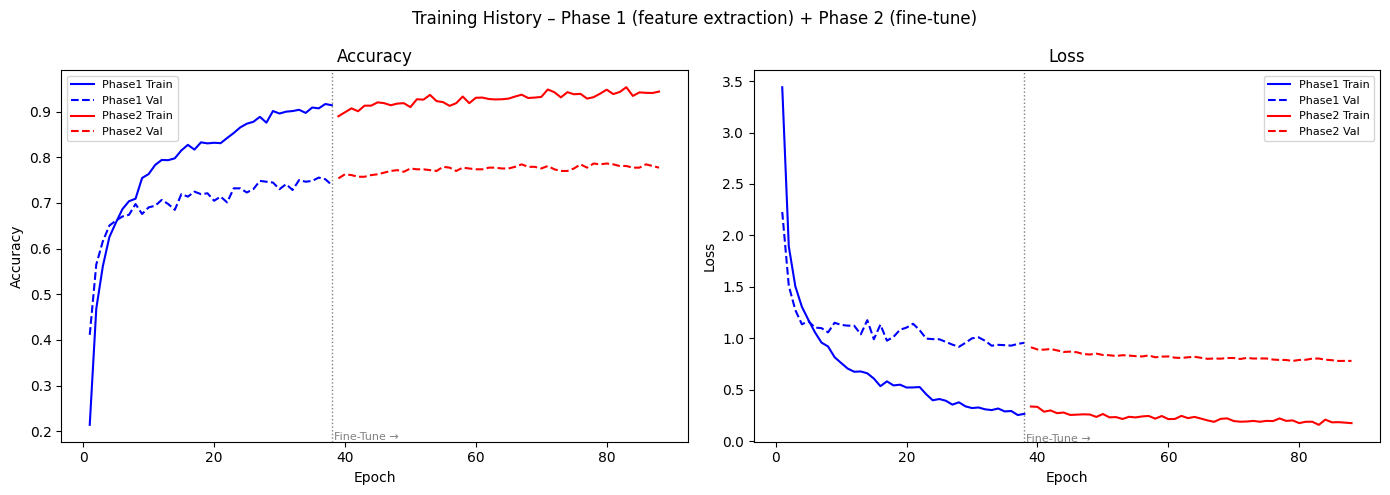

Saved → saved_models/training_history.png


In [19]:
try:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, metric, title in zip(
        axes,
        ('accuracy', 'loss'),
        ('Accuracy', 'Loss')
    ):
        p1_train = history_phase1.history[metric]
        p1_val   = history_phase1.history[f'val_{metric}']
        p2_train = history_phase2.history[metric]
        p2_val   = history_phase2.history[f'val_{metric}']

        epochs_p1 = range(1, len(p1_train)+1)
        epochs_p2 = range(len(p1_train)+1, len(p1_train)+len(p2_train)+1)

        ax.plot(epochs_p1, p1_train, 'b-',   label='Phase1 Train')
        ax.plot(epochs_p1, p1_val,   'b--',  label='Phase1 Val')
        ax.plot(epochs_p2, p2_train, 'r-',   label='Phase2 Train')
        ax.plot(epochs_p2, p2_val,   'r--',  label='Phase2 Val')
        ax.axvline(len(p1_train), color='gray', linestyle=':', linewidth=1)
        ax.text(len(p1_train)+0.3, ax.get_ylim()[0]*1.02,
                'Fine-Tune →', fontsize=8, color='gray')
        ax.set_xlabel('Epoch'); ax.set_ylabel(title); ax.set_title(title)
        ax.legend(fontsize=8)

    plt.suptitle('Training History – Phase 1 (feature extraction) + Phase 2 (fine-tune)',
                 fontsize=12)
    plt.tight_layout()
    plt.savefig('saved_models/training_history.png', dpi=150)
    plt.show()
    print('Saved → saved_models/training_history.png')

except NameError:
    print('history_phase1 / history_phase2 not found.'
          '  Run the training cells first, or skip this cell.')


---
# 13. Real-World Test: Classify `Some_tests/` Images
Loads the saved weights and classifies every image in `Some_tests/`.

Outputs:
- Console table: predicted pose + confidence
- Detailed top-5 breakdown per image
- Visual grid saved to `saved_models/some_tests_results.png`


## 13.1 - Load Model (reuse from session or reload)


In [22]:
import os, json
import numpy as np
import matplotlib
matplotlib.use('Agg')  # headless – works in Jupyter too
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import (Dense, GlobalAveragePooling2D,
                                     Dropout, BatchNormalization, Input)
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

DATASET_DIR  = r'd:\Yoga Website\Dataset'
WEIGHTS_PATH = r'd:\Yoga Website\saved_models\efficientnetb0_yoga.weights.h5'
TEST_DIR     = r'd:\Yoga Website\Some_tests'
IMG_SIZE     = (224, 224)
VALID_EXT    = {'.jpg', '.jpeg', '.png', '.webp'}

classes = sorted([
    d for d in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, d))
])
NUM_CLASSES = len(classes)

# Re-use model already in session if possible
try:
    _ = eval_model
    test_model = eval_model
    print(f'Reusing eval_model already in session. ({NUM_CLASSES} classes)')
except NameError:
    print('Building model from scratch...')
    inputs     = Input(shape=(*IMG_SIZE, 3))
    base_model = EfficientNetB0(weights='imagenet', include_top=False,
                                input_tensor=inputs)
    base_model.trainable = True
    for layer in base_model.layers[:150]:
        layer.trainable = False
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dense(512, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)
    outputs = Dense(NUM_CLASSES, activation='softmax')(x)
    test_model = Model(inputs=inputs, outputs=outputs)
    test_model.load_weights(WEIGHTS_PATH)
    print(f'Weights loaded. ({NUM_CLASSES} classes)')


Reusing eval_model already in session. (47 classes)


## 13.2 - Run Inference on All Test Images


In [23]:
test_images = sorted([
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if os.path.splitext(f)[1].lower() in VALID_EXT
])
print(f'Test images found: {len(test_images)}')

results = []
for img_path in test_images:
    img  = load_img(img_path, target_size=IMG_SIZE)
    arr  = img_to_array(img)[np.newaxis, ...]
    prob = test_model.predict(arr, verbose=0)[0]
    top5_idx = np.argsort(prob)[-5:][::-1]
    results.append({
        'path':       img_path,
        'filename':   os.path.basename(img_path),
        'top1_class': classes[top5_idx[0]],
        'top1_conf':  float(prob[top5_idx[0]]),
        'top5':       [(classes[i], float(prob[i])) for i in top5_idx],
    })

# Summary table
LINE = '-' * 72
print(LINE)
print(f'  {"#":<3}  {"Predicted Class":<35}  {"Conf":>6}  Image File')
print(LINE)
for i, r in enumerate(results, 1):
    fname = r['filename'][:30]
    conf  = r['top1_conf'] * 100
    flag  = 'HIGH' if conf >= 70 else 'MED' if conf >= 45 else 'LOW'
    print(f'  {i:<3}  {r["top1_class"]:<35}  {conf:5.1f}%  [{flag}] {fname}')
print(LINE)


Test images found: 14
------------------------------------------------------------------------
  #    Predicted Class                        Conf  Image File
------------------------------------------------------------------------
  1    Bitilasana                            63.2%  [MED] WhatsApp Image 2026-04-20 at 1
  2    Vrksasana                             86.9%  [HIGH] WhatsApp Image 2026-04-20 at 1
  3    Garudasana                            70.2%  [HIGH] WhatsApp Image 2026-04-20 at 1
  4    Baddha Konasana                       46.9%  [MED] WhatsApp Image 2026-04-20 at 1
  5    Bitilasana                            88.0%  [HIGH] WhatsApp Image 2026-04-20 at 1
  6    Dhanurasana                           92.1%  [HIGH] WhatsApp Image 2026-04-20 at 1
  7    Vrksasana                             99.6%  [HIGH] WhatsApp Image 2026-04-20 at 1
  8    Uttanasana                            22.2%  [LOW] WhatsApp Image 2026-04-20 at 1
  9    Balasana                              97.5%  

## 13.3 - Detailed Top-5 Predictions per Image


In [24]:
for i, r in enumerate(results, 1):
    print(f'[{i}] {r["filename"]}')
    for rank, (cls, c) in enumerate(r['top5'], 1):
        bar = '#' * int(c * 30)
        print(f'     {rank}. {cls:<35} {c*100:5.1f}%  {bar}')
    print()


[1] WhatsApp Image 2026-04-20 at 10.10.15 PM (1).jpeg
     1. Bitilasana                           63.2%  ##################
     2. Baddha Konasana                      10.5%  ###
     3. Paschimottanasana                     7.0%  ##
     4. Vasisthasana                          4.1%  #
     5. Parsvottanasana                       2.7%  

[2] WhatsApp Image 2026-04-20 at 10.10.15 PM (2).jpeg
     1. Vrksasana                            86.9%  ##########################
     2. Utkatasana                            6.5%  #
     3. Garudasana                            5.9%  #
     4. Eka Pada Rajakapotasana               0.3%  
     5. Hanumanasana                          0.2%  

[3] WhatsApp Image 2026-04-20 at 10.10.15 PM.jpeg
     1. Garudasana                           70.2%  #####################
     2. Vrksasana                            22.5%  ######
     3. Baddha Konasana                       5.0%  #
     4. Padmasana                             1.3%  
     5. Utkatasana

## 13.4 - Visual Grid
Each tile shows the image, predicted label, confidence bar, and top-3 breakdown.
- **Green** title = confidence >= 70%
- **Orange** title = confidence 45-70%
- **Red** title = confidence < 45% (model is uncertain)


In [25]:
N    = len(results)
COLS = 4
ROWS = (N + COLS - 1) // COLS

fig, axes = plt.subplots(ROWS, COLS, figsize=(COLS * 4, ROWS * 5.2))
axes = axes.flatten()
fig.patch.set_facecolor('#1a1a2e')

for ax, r in zip(axes, results):
    img = load_img(r['path'], target_size=(300, 300))
    ax.imshow(img)
    ax.axis('off')
    ax.set_facecolor('#1a1a2e')

    conf  = r['top1_conf']
    color = '#2ecc71' if conf >= 0.70 else '#f39c12' if conf >= 0.45 else '#e74c3c'

    # Background bar
    ax.add_patch(patches.FancyBboxPatch(
        (0.02, 0.01), 0.96, 0.055,
        boxstyle='round,pad=0.01', linewidth=0,
        facecolor='#222222cc', transform=ax.transAxes, clip_on=False))
    # Confidence bar
    ax.add_patch(patches.FancyBboxPatch(
        (0.02, 0.01), 0.96 * conf, 0.055,
        boxstyle='round,pad=0.01', linewidth=0,
        facecolor=color, transform=ax.transAxes, clip_on=False))

    ax.set_title(
        f'{r["top1_class"][:28]}\n{conf*100:.1f}% confidence',
        fontsize=8.5, color=color, fontweight='bold', pad=4
    )

    top3_text = '\n'.join(
        f'  {cls[:22]}: {c*100:.1f}%' for cls, c in r['top5'][:3]
    )
    ax.text(0.5, -0.10, top3_text,
            transform=ax.transAxes, fontsize=6.2,
            va='top', ha='center', color='#cccccc',
            bbox=dict(facecolor='#111111cc', edgecolor='none', pad=3))

# Hide empty axes
for ax in axes[len(results):]:
    ax.set_visible(False)

fig.suptitle('Yoga Pose Classification - Some_tests Results',
             fontsize=14, color='white', y=1.01)
plt.tight_layout(rect=[0, 0.05, 1, 1])

out_path = r'd:\Yoga Website\saved_models\some_tests_results.png'
os.makedirs('saved_models', exist_ok=True)
plt.savefig(out_path, dpi=140, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print(f'Saved -> {out_path}')


Saved -> d:\Yoga Website\saved_models\some_tests_results.png


C:\Users\ABHIROOP\AppData\Local\Temp\ipykernel_6460\2348163251.py:54: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 13.5 - Confidence Summary Bar Chart
Ranks all 14 predictions from most to least confident.


In [26]:
labels_plot = [f'#{i+1} {r["top1_class"][:24]}' for i, r in enumerate(results)]
confs_plot  = [r['top1_conf'] * 100 for r in results]
colors_plot = ['#2ecc71' if c >= 70 else '#f39c12' if c >= 45 else '#e74c3c'
               for c in confs_plot]

# Sort by confidence descending
order = sorted(range(len(confs_plot)), key=lambda x: confs_plot[x], reverse=True)
labels_s = [labels_plot[i] for i in order]
confs_s  = [confs_plot[i]  for i in order]
colors_s = [colors_plot[i] for i in order]

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('#1a1a2e')
ax.set_facecolor('#1a1a2e')

bars = ax.barh(range(len(confs_s)), confs_s, color=colors_s,
               edgecolor='none', height=0.65)
ax.set_yticks(range(len(labels_s)))
ax.set_yticklabels(labels_s, fontsize=9, color='white')
ax.set_xlabel('Confidence (%)', fontsize=11, color='white')
ax.set_title('Test Image Prediction Confidence (sorted)',
             fontsize=12, color='white', pad=12)
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_edgecolor('#444444')
ax.axvline(70, color='#2ecc71', linestyle='--', linewidth=0.8, alpha=0.7)
ax.axvline(45, color='#f39c12', linestyle='--', linewidth=0.8, alpha=0.7)
ax.set_xlim(0, 108)
for bar, val in zip(bars, confs_s):
    ax.text(val + 0.8, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%', va='center', fontsize=8.5, color='white')

plt.tight_layout()
plt.savefig('saved_models/some_tests_confidence.png', dpi=150,
            bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
print('Saved -> saved_models/some_tests_confidence.png')

# Quick stats
c_arr = np.array(confs_plot)
print(f'\nAverage confidence : {c_arr.mean():.1f}%')
print(f'High (>=70%)       : {(c_arr>=70).sum()} / {len(c_arr)} images')
print(f'Medium (45-70%)    : {((c_arr>=45)&(c_arr<70)).sum()} / {len(c_arr)} images')
print(f'Low (<45%)         : {(c_arr<45).sum()} / {len(c_arr)} images')


Saved -> saved_models/some_tests_confidence.png

Average confidence : 70.6%
High (>=70%)       : 8 / 14 images
Medium (45-70%)    : 3 / 14 images
Low (<45%)         : 3 / 14 images


C:\Users\ABHIROOP\AppData\Local\Temp\ipykernel_6460\1879168842.py:36: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
